In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

In [4]:
df = pd.read_csv("/content/sample_data/Churn_Modelling.csv")

In [5]:
print(df.shape)
print(df.head())
print(df.isnull().sum())

(10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4

In [6]:
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

In [7]:
df = pd.get_dummies(
    df, columns=['Geography', 'Gender'], drop_first=True
)

In [9]:
X = df.drop('Exited', axis=1)
y = df['Exited']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=0
)


In [10]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)


In [11]:
ann = MLPClassifier(
    hidden_layer_sizes=(100, 100),
    max_iter=100,
    activation='relu',
    random_state=0
)

ann.fit(X_train, y_train)
y_pred = ann.predict(X_test)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


In [12]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.844
              precision    recall  f1-score   support

           0       0.89      0.92      0.90      2379
           1       0.64      0.55      0.59       621

    accuracy                           0.84      3000
   macro avg       0.77      0.74      0.75      3000
weighted avg       0.84      0.84      0.84      3000



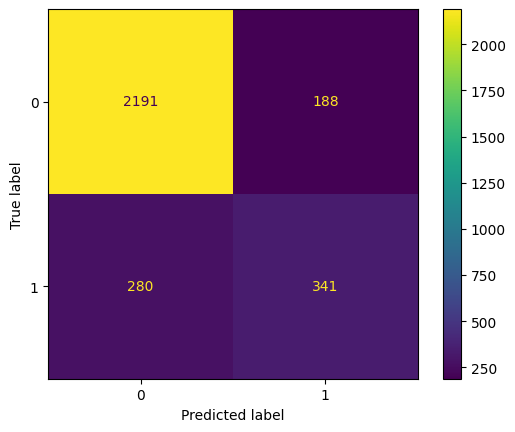

In [13]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()